<a href="https://colab.research.google.com/github/Ajay9760/Ajay9760/blob/main/EDA_Complete_Cardiotocographic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Complete EDA + ML Workflow — Cardiotocographic Dataset

This notebook performs the complete workflow requested:

1. Load the dataset
2. Inspect shape, size, dtypes and descriptive statistics
3. Check missing values
4. Handle missing values
5. Check duplicates
6. Validate the target (`NSP`)
7. Visualize target distribution and feature distributions
8. Correlation analysis
9. Outlier detection and capping
10. Separate features (`X`) and target (`y`)
11. Feature selection using ANOVA F-test
12. Train/test split
13. StandardScaler
14. Logistic Regression
15. Random Forest
16. Accuracy, precision, recall, F1 and confusion matrices

**Important:** the uploaded file has a malformed `NSP` target. The original UCI Cardiotocography target is a 3-class label (1, 2, 3). The uploaded file contains 111 distinct numeric NSP values, including invalid values such as -1 and 5. Therefore, the notebook includes a clearly marked **diagnostic-only** path that rounds near-integer NSP values and removes the 10 rows that still become invalid. This is NOT a substitute for obtaining the original labels and should not be presented as a final clinical/production model.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


In [2]:
# 1. Load data
df = pd.read_csv("Cardiotocographic.csv")

print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()


Shape: (2126, 14)
Rows: 2126
Columns: 14


,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,MLTV,Width,Tendency,NSP
0,120.000000,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,2.4,64.0,0.999926,2.0
1,132.000000,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,10.4,130.0,0.000000,1.0
2,133.000000,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,13.4,130.0,0.000000,1.0
3,134.000000,0.002561,0.0,0.007742,0.002561,0.0,0.0,16.0,2.4,0.0,23.0,117.0,1.000000,1.0
4,131.948232,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,19.9,117.0,1.000000,1.0


In [3]:
# 2. Basic inspection
print("df.size =", df.size)
print("\ndf.shape =", df.shape)
print("\nData types / non-null counts:")
df.info()


df.size = 29764

df.shape = (2126, 14)

Data types / non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   LB        2105 non-null   float64
 1   AC        2106 non-null   float64
 2   FM        2126 non-null   float64
 3   UC        2126 non-null   float64
 4   DL        2126 non-null   float64
 5   DS        2105 non-null   float64
 6   DP        2105 non-null   float64
 7   ASTV      2126 non-null   float64
 8   MSTV      2126 non-null   float64
 9   ALTV      2126 non-null   float64
 10  MLTV      2105 non-null   float64
 11  Width     2105 non-null   float64
 12  Tendency  2105 non-null   float64
 13  NSP       2105 non-null   float64
dtypes: float64(14)
memory usage: 232.7 KB


In [4]:
# 3. Descriptive statistics
df.describe().T


,count,mean,std,min,25%,50%,75%,max
LB,2105.0,133.343598,11.270154,51.842487,126.000000,133.000000,140.000000,214.000000
AC,2106.0,0.003219,0.004391,-0.019284,0.000000,0.001634,0.005650,0.038567
FM,2126.0,0.009894,0.067540,-0.480634,0.000000,0.000000,0.002567,0.961268
UC,2126.0,0.004391,0.003340,-0.014925,0.001851,0.004484,0.006536,0.030002
DL,2126.0,0.001895,0.003343,-0.015393,0.000000,0.000000,0.003289,0.030769
DS,2105.0,0.000003,0.000142,-0.001353,0.000000,0.000000,0.000000,0.002706
DP,2105.0,0.000175,0.000840,-0.005348,0.000000,0.000000,0.000000,0.010695
ASTV,2126.0,46.995984,18.813973,-63.000000,32.000000,49.000000,61.000000,162.000000
MSTV,2126.0,1.364378,1.173632,-6.600000,0.700000,1.200000,1.700000,13.800000
ALTV,2126.0,10.285964,21.205041,-91.000000,0.000000,0.000000,11.000000,182.000000


In [5]:
# 4. Missing values
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    "Missing": missing,
    "Missing_%": missing_pct
})
missing_report[missing_report["Missing"] > 0]


,Missing,Missing_%
LB,21,0.99
DS,21,0.99
MLTV,21,0.99
Width,21,0.99
Tendency,21,0.99
DP,21,0.99
NSP,21,0.99
AC,20,0.94


In [6]:
# 5. Overall missing percentage
overall_missing_pct = df.isna().sum().sum() / df.size * 100
print(f"Overall missing cells: {df.isna().sum().sum()}")
print(f"Overall missing percentage: {overall_missing_pct:.3f}%")

Overall missing cells: 167
Overall missing percentage: 0.561%


In [7]:
# 6. Handle missing values
# Because only 21 rows contain missing values in several columns, this is a simple option.
df_clean = df.dropna(axis=0).copy()

print("Before:", df.shape)
print("After :", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("\nRemaining missing values:")
print(df_clean.isna().sum().sum())


Before: (2126, 14)
After : (2105, 14)
Rows removed: 21

Remaining missing values:
0


In [8]:
# 7. Duplicate check
duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows:", duplicate_count)

# If duplicates are confirmed to be accidental, remove them:
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df_clean.shape)


Duplicate rows: 2
Shape after duplicate removal: (2103, 14)


In [9]:
# 8. Validate the target BEFORE modeling
print("NSP unique values:", df_clean["NSP"].nunique())
print("First 30 NSP values:")
print(np.sort(df_clean["NSP"].unique())[:30])

print("\nNSP minimum:", df_clean["NSP"].min())
print("NSP maximum:", df_clean["NSP"].max())


NSP unique values: 111
First 30 NSP values:
[-1.025988   -1.          0.9670755   0.96944689  0.97230458  0.97544038
  0.97817368  0.97927954  0.97973798  0.98122639  0.98145959  0.98342028
  0.98479205  0.98483388  0.98749813  0.98839285  0.98839898  0.98900567
  0.98925697  0.98952542  0.98986216  0.99106613  0.99120013  0.99167495
  0.99223419  0.99284679  0.99369481  0.99379572  0.99391695  0.99418412]

NSP minimum: -1.025988003
NSP maximum: 5.0


## Target validation result

For the standard UCI Cardiotocography task, `NSP` is a **three-class categorical target**:

- `1` = Normal
- `2` = Suspect
- `3` = Pathological


Do **not** use `StandardScaler`, outlier capping, regression, or arbitrary conversion on `NSP`. It is a class label, not a continuous feature.


In [10]:
# 9. Diagnostic-only target repair
# This is ONLY to allow us to execute the rest of the ML workflow on the supplied file.
# It rounds near-integer target values and keeps only resulting classes 1, 2, 3.
#
# DO NOT use this as the final scientific/clinical label-cleaning procedure.

df_model = df_clean.copy()
df_model["NSP_diagnostic"] = df_model["NSP"].round().astype(int)

invalid_mask = ~df_model["NSP_diagnostic"].isin([1, 2, 3])

print("Rows after missing-value/duplicate cleaning:", len(df_model))
print("Invalid target rows after rounding:", invalid_mask.sum())

df_model = df_model.loc[~invalid_mask].copy()
df_model["NSP_diagnostic"] = df_model["NSP_diagnostic"].astype(int)

print("\nDiagnostic class distribution:")
print(df_model["NSP_diagnostic"].value_counts().sort_index())


Rows after missing-value/duplicate cleaning: 2103
Invalid target rows after rounding: 10

Diagnostic class distribution:
NSP_diagnostic
1    1628
2     293
3     172
Name: count, dtype: int64


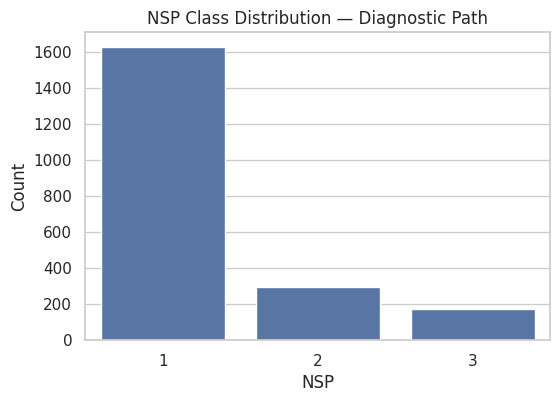

NSP_diagnostic
1    77.78
2    14.00
3     8.22
Name: proportion, dtype: float64


In [11]:
# 10. Target distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df_model, x="NSP_diagnostic")
plt.title("NSP Class Distribution — Diagnostic Path")
plt.xlabel("NSP")
plt.ylabel("Count")
plt.show()

print(df_model["NSP_diagnostic"].value_counts(normalize=True).sort_index().mul(100).round(2))


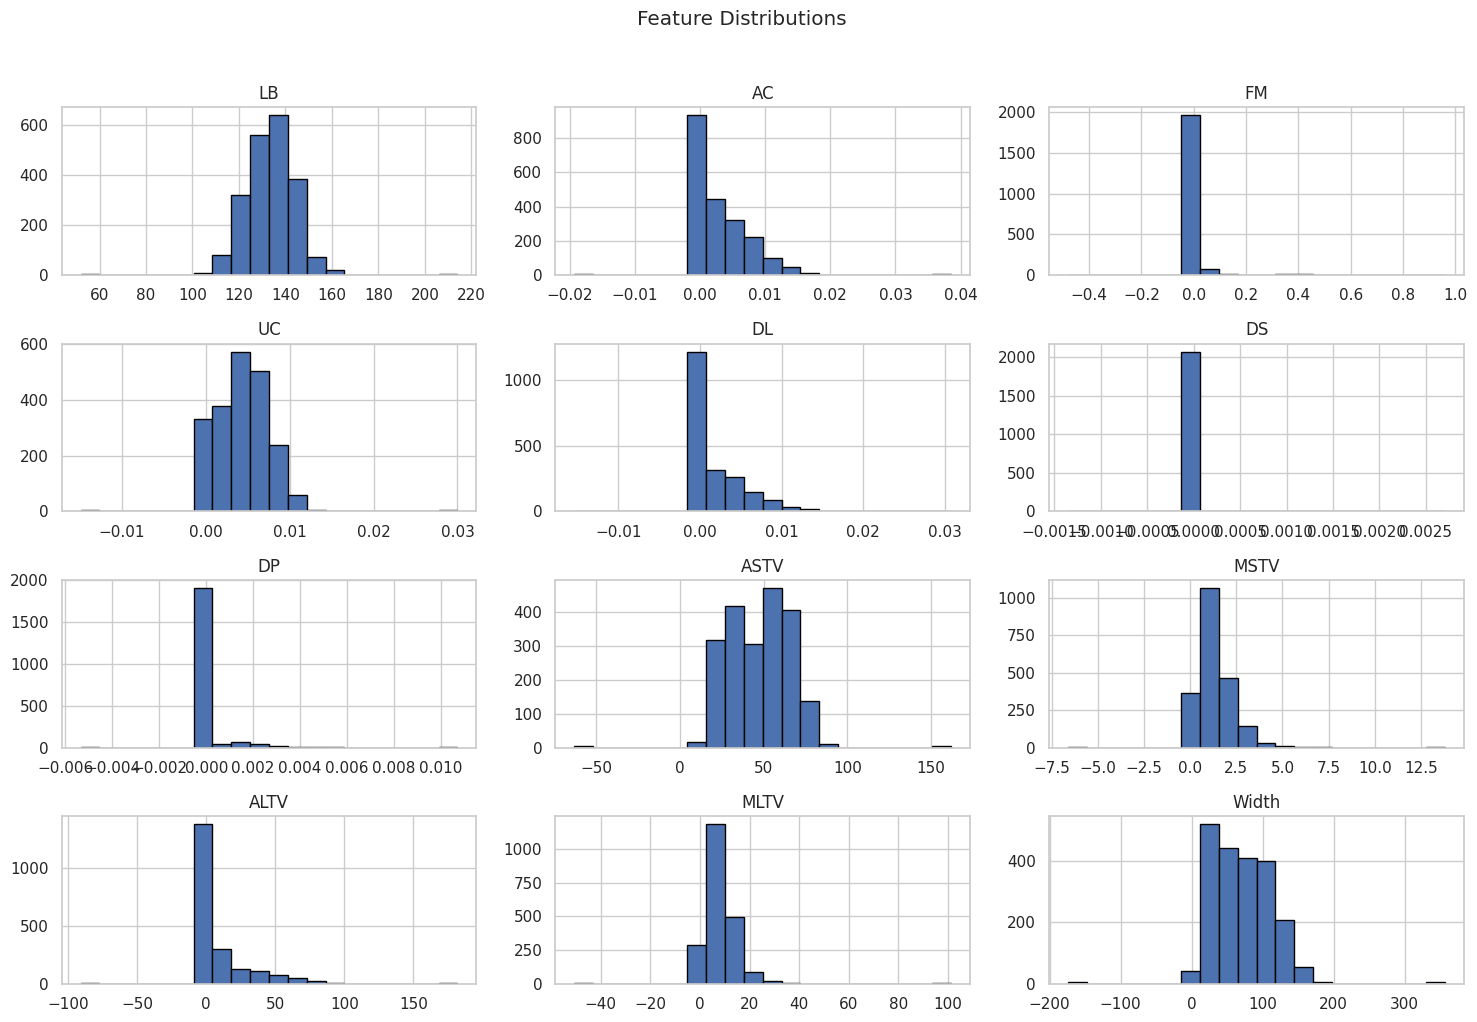

In [12]:
# 11. Histograms for numeric features
feature_cols = [c for c in df_model.columns if c not in ["NSP", "NSP_diagnostic", "Tendency"]]

df_model[feature_cols].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor="black"
)
plt.suptitle("Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()


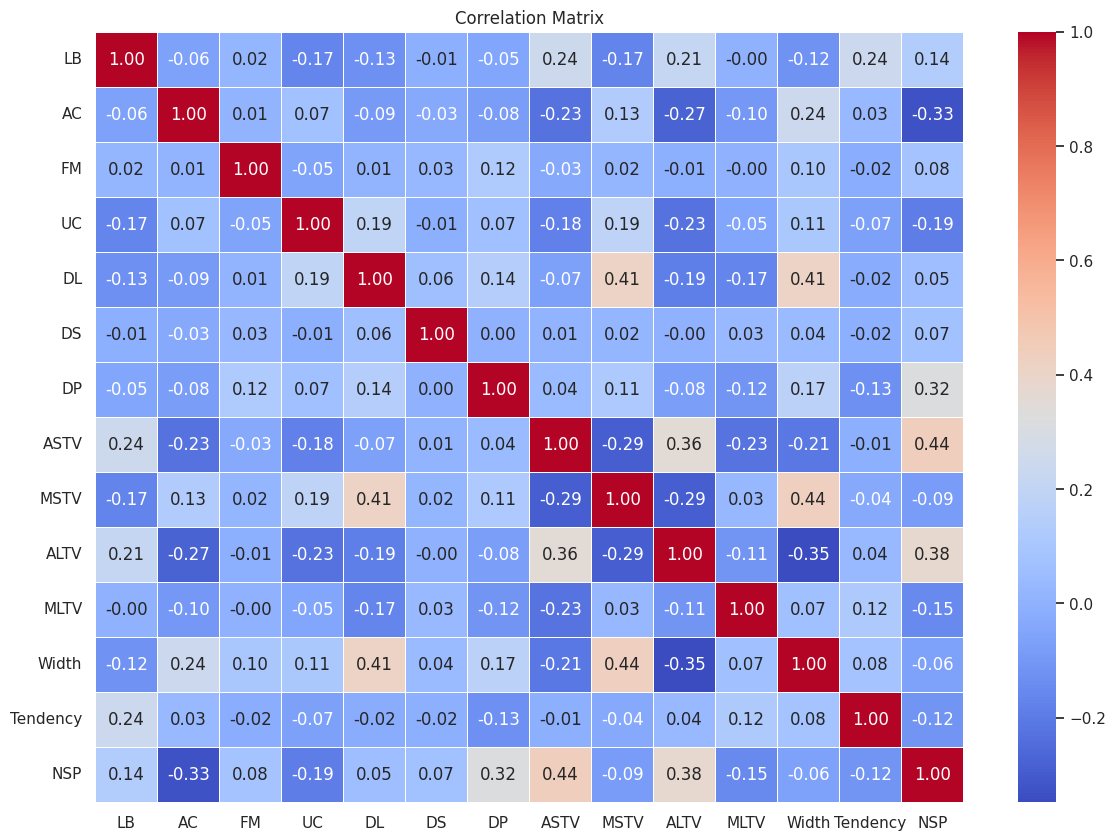

In [13]:
# 12. Correlation matrix
numeric_for_corr = df_model.drop(columns=["NSP_diagnostic"])
corr = numeric_for_corr.corr(numeric_only=True)

plt.figure(figsize=(14,10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()


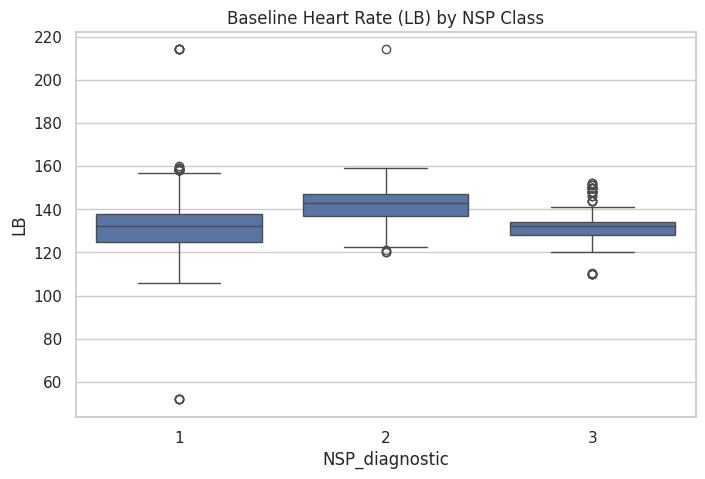

In [14]:
# 13. Feature vs target example
plt.figure(figsize=(8,5))
sns.boxplot(data=df_model, x="NSP_diagnostic", y="LB")
plt.title("Baseline Heart Rate (LB) by NSP Class")
plt.show()


In [15]:
# 14. Outlier detection using IQR
# Outliers are assessed on X only. The target is NEVER treated as an outlier.
X_before = df_model.drop(columns=["NSP", "NSP_diagnostic", "Tendency"]).copy()

outlier_report = []

for col in X_before.columns:
    q1 = X_before[col].quantile(0.25)
    q3 = X_before[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((X_before[col] < lower) | (X_before[col] > upper)).sum()

    outlier_report.append([col, q1, q3, iqr, lower, upper, count])

outlier_report = pd.DataFrame(
    outlier_report,
    columns=["Feature","Q1","Q3","IQR","Lower_Bound","Upper_Bound","Outlier_Count"]
)

outlier_report.sort_values("Outlier_Count", ascending=False)


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count
2,FM,0.000000,0.002554,0.002554,-0.003831,0.006386,340
9,ALTV,0.000000,11.000000,11.000000,-16.500000,27.500000,317
6,DP,0.000000,0.000000,0.000000,0.000000,0.000000,283
4,DL,0.000000,0.003289,0.003289,-0.004934,0.008224,122
5,DS,0.000000,0.000000,0.000000,0.000000,0.000000,120
10,MLTV,4.600000,10.900000,6.300000,-4.850000,20.350000,80
8,MSTV,0.700000,1.700000,1.000000,-0.800000,3.200000,77
1,AC,0.000000,0.005624,0.005624,-0.008436,0.014061,41
3,UC,0.001821,0.006536,0.004714,-0.005250,0.013608,13
0,LB,126.000000,140.041769,14.041769,104.937347,161.104422,10


In [16]:
# 15. IQR capping on features
X = X_before.copy()

for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    X[col] = X[col].clip(lower, upper)

print("Outlier capping completed on X.")
print("NSP was not included.")


Outlier capping completed on X.
NSP was not included.


## Why we do not cap `NSP`

`NSP` is the class we are trying to predict.

For a classification problem:

- `X` = input features
- `y` = target/class

If `NSP = 1`, that does not mean "a small numeric measurement".
It means "Class 1".

Therefore, values such as `1`, `2`, and `3` are categories. They are not observations from a continuous distribution, so IQR outlier treatment is inappropriate.


In [17]:
# 16. Define target
y = df_model["NSP_diagnostic"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget classes:")
print(sorted(y.unique()))


X shape: (2093, 12)
y shape: (2093,)

Target classes:
[np.int64(1), np.int64(2), np.int64(3)]


## Correct feature-selection order

A major improvement over the original notebook is the ordering.

The original notebook performs ANOVA feature selection on the full dataset **before** train/test splitting. That leaks information from the test set into the feature-selection process.

Correct order:

**Split → fit feature selector on training data → transform train/test**

This keeps the test set genuinely unseen.


In [18]:
# 17. Train/test split BEFORE feature selection
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (1674, 12)
X_test : (419, 12)
y_train: (1674,)
y_test : (419,)


In [19]:
# 18. ANOVA feature selection — fit ONLY on training data
selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X_train, y_train)

anova_scores = pd.DataFrame({
    "Feature": X_train.columns,
    "F_Score": selector.scores_,
    "p_value": selector.pvalues_
}).sort_values("F_Score", ascending=False)

anova_scores


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [5 6] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,Feature,F_Score,p_value
9,ALTV,307.290583,2.265290e-114
7,ASTV,273.909626,1.294062e-103
1,AC,154.006489,4.111338e-62
8,MSTV,119.184031,4.106936e-49
0,LB,102.858059,7.452589e-43
3,UC,77.782464,5.019791e-33
10,MLTV,59.563487,1.028913e-25
11,Width,45.805016,4.298209e-20
4,DL,37.451061,1.228015e-16
2,FM,12.775902,3.115233e-06


In [20]:
# 19. Select the top 9 features
k = min(9, X_train.shape[1])

top_features = anova_scores.head(k)["Feature"].tolist()
print("Selected features:")
print(top_features)

X_train_selected = X_train[top_features].copy()
X_test_selected = X_test[top_features].copy()


Selected features:
['ALTV', 'ASTV', 'AC', 'MSTV', 'LB', 'UC', 'MLTV', 'Width', 'DL']


In [21]:
# 20. StandardScaler
# IMPORTANT:
# fit_transform() only on training data
# transform() on test data

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("Scaling complete.")


Scaling complete.


## What StandardScaler is doing

For each feature:

`z = (x - mean) / standard_deviation`

The mean and standard deviation are learned from **X_train only**.

Why?

If we calculate scaling statistics using X_test too, information from the test set leaks into training.

Scaling is especially useful for Logistic Regression because its optimization is sensitive to feature scale. Tree models such as Random Forest generally do not require scaling, although using the same transformed matrix is acceptable.


In [22]:
# 21. Logistic Regression
lr = LogisticRegression(max_iter=2000)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("Logistic Regression")
print("Accuracy :", accuracy_score(y_test, lr_pred))
print("Precision:", precision_score(y_test, lr_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_test, lr_pred, average="macro", zero_division=0))
print("F1       :", f1_score(y_test, lr_pred, average="macro", zero_division=0))

print("\nClassification report:")
print(classification_report(y_test, lr_pred, zero_division=0))


Logistic Regression
Accuracy : 0.863961813842482
Precision: 0.7657122065636187
Recall   : 0.6540898776064444
F1       : 0.6964085297418631

Classification report:
              precision    recall  f1-score   support

           1       0.90      0.97      0.93       326
           2       0.63      0.53      0.57        59
           3       0.76      0.47      0.58        34

    accuracy                           0.86       419
   macro avg       0.77      0.65      0.70       419
weighted avg       0.85      0.86      0.85       419



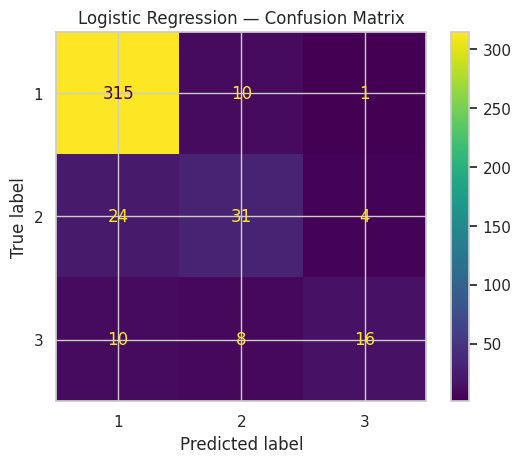

In [23]:
# 22. Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, lr_pred)
plt.title("Logistic Regression — Confusion Matrix")
plt.show()


In [24]:
# 23. Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)

print("Random Forest")
print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred, average="macro", zero_division=0))
print("Recall   :", recall_score(y_test, rf_pred, average="macro", zero_division=0))
print("F1       :", f1_score(y_test, rf_pred, average="macro", zero_division=0))

print("\nClassification report:")
print(classification_report(y_test, rf_pred, zero_division=0))


Random Forest
Accuracy : 0.9212410501193318
Precision: 0.8903289422025719
Recall   : 0.7942073574776692
F1       : 0.8350509837160324

Classification report:
              precision    recall  f1-score   support

           1       0.93      0.99      0.96       326
           2       0.84      0.63      0.72        59
           3       0.90      0.76      0.83        34

    accuracy                           0.92       419
   macro avg       0.89      0.79      0.84       419
weighted avg       0.92      0.92      0.92       419



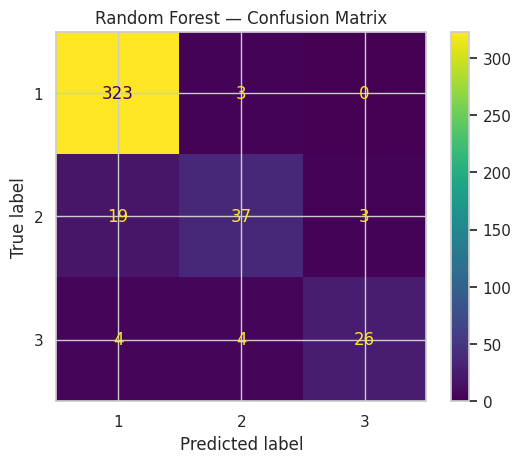

In [25]:
# 24. Random Forest confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred)
plt.title("Random Forest — Confusion Matrix")
plt.show()


In [26]:
# 25. Model comparison
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Macro_Precision": [
        precision_score(y_test, lr_pred, average="macro", zero_division=0),
        precision_score(y_test, rf_pred, average="macro", zero_division=0)
    ],
    "Macro_Recall": [
        recall_score(y_test, lr_pred, average="macro", zero_division=0),
        recall_score(y_test, rf_pred, average="macro", zero_division=0)
    ],
    "Macro_F1": [
        f1_score(y_test, lr_pred, average="macro", zero_division=0),
        f1_score(y_test, rf_pred, average="macro", zero_division=0)
    ]
})

comparison.sort_values("Macro_F1", ascending=False)


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
1,Random Forest,0.921241,0.890329,0.794207,0.835051
0,Logistic Regression,0.863962,0.765712,0.654090,0.696409


# Final conclusion

The workflow is now structurally correct:

**Load → Inspect → Missing values → Duplicates → Validate target → EDA → Outliers on X → Split → Feature selection on train only → Scaling on train only → Model → Evaluation**

However, the uploaded file's `NSP` labels are not trustworthy. The diagnostic model path rounds the noisy target and removes invalid labels solely so the operations can be demonstrated.

For a final model, replace the supplied CSV with the original UCI Cardiotocography data and rerun the notebook without the diagnostic target-repair step.
